DATA PREPROCESSING

In [19]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

df=pd.read_csv("Employee.csv")

1-Data Exploration

In [20]:
df.shape

(148, 6)

In [21]:
df.head()

,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Company  140 non-null    str    
 1   Age      130 non-null    float64
 2   Salary   124 non-null    float64
 3   Place    134 non-null    str    
 4   Country  148 non-null    str    
 5   Gender   148 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 9.4 KB


In [23]:
print("\nunique values and lengths: ")
for col in df.columns:
    print(f"\\n{col}:Length={len(df[col])},Unique count={df[col].nunique()},Values={df[col].unique()}")

df.describe(include="all")


unique values and lengths: 
\nCompany:Length=148,Unique count=6,Values=<ArrowStringArray>
[                      'TCS',                   'Infosys',
                       'CTS',                         nan,
 'Tata Consultancy Services',                'Congnizant',
           'Infosys Pvt Lmt']
Length: 7, dtype: str
\nAge:Length=148,Unique count=29,Values=[20. 30. 35. 40. 23. nan 34. 45. 18. 22. 32. 37. 50. 21. 46. 36. 26. 41.
 24. 25. 43. 19. 38. 51. 31. 44. 33. 17.  0. 54.]
\nSalary:Length=148,Unique count=40,Values=[  nan 2300. 3000. 4000. 5000. 6000. 7000. 8000. 9000. 1089. 1234. 3030.
 3045. 3184. 4824. 5835. 7084. 8943. 8345. 9284. 9876. 2034. 7654. 2934.
 4034. 5034. 8202. 9024. 4345. 6544. 6543. 3234. 4324. 5435. 5555. 8787.
 3454. 5654. 5009. 5098. 3033.]
\nPlace:Length=148,Unique count=11,Values=<ArrowStringArray>
[   'Chennai',     'Mumbai',   'Calcutta',      'Delhi', 'Podicherry',
     'Cochin',          nan,      'Noida',  'Hyderabad',     'Bhopal',
     'Nagpur',      

,Company,Age,Salary,Place,Country,Gender
count,140,130.000000,124.000000,134,148,148.000000
unique,6,NaN,NaN,11,1,NaN
top,TCS,NaN,NaN,Mumbai,India,NaN
freq,53,NaN,NaN,37,148,NaN
mean,NaN,30.484615,5312.467742,NaN,NaN,0.222973
std,NaN,11.096640,2573.764683,NaN,NaN,0.417654
min,NaN,0.000000,1089.000000,NaN,NaN,0.000000
25%,NaN,22.000000,3030.000000,NaN,NaN,0.000000
50%,NaN,32.500000,5000.000000,NaN,NaN,0.000000
75%,NaN,37.750000,8000.000000,NaN,NaN,0.000000


2-Data Cleaning

In [24]:
df["Age"]=df["Age"].replace(0, np.nan)

print("Duplicates before: ",df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates after: ",df.duplicated().sum())

df["Company"] = df["Company"].replace({'Tata Consultancy Services':'TCS', 'Cognizant':'CTS', 'Infosys Pvt Lmt':'Infosys'})


df['Age'] = df['Age'].fillna(df['Age'].median())
df['Company'] = df['Company'].fillna(df['Company'].mode()[0])
df['Salary'] = df['Salary'].fillna(df['Salary'].median())
df['Place'] = df['Place'].fillna(df['Place'].mode()[0])

print("\nMissing Values after Cleaning :\n",df.isnull().sum())

Duplicates before:  4
Duplicates after:  0

Missing Values after Cleaning :
 Company    0
Age        0
Salary     0
Place      0
Country    0
Gender     0
dtype: int64


3-Data Analysis

Total employees: 15


,Company,Age,Salary,Place,Country,Gender
21,Infosys,50.0,3184.0,Delhi,India,0
32,Infosys,45.0,4034.0,Calcutta,India,0
39,Infosys,41.0,3000.0,Mumbai,India,0
50,Infosys,41.0,3000.0,Chennai,India,0
57,Infosys,51.0,3184.0,Hyderabad,India,0



Employee count by place:
 Place
Mumbai        48
Calcutta      32
Chennai       14
Delhi         14
Cochin        13
Noida          8
Hyderabad      8
Podicherry     3
Pune           2
Bhopal         1
Nagpur         1
Name: count, dtype: int64


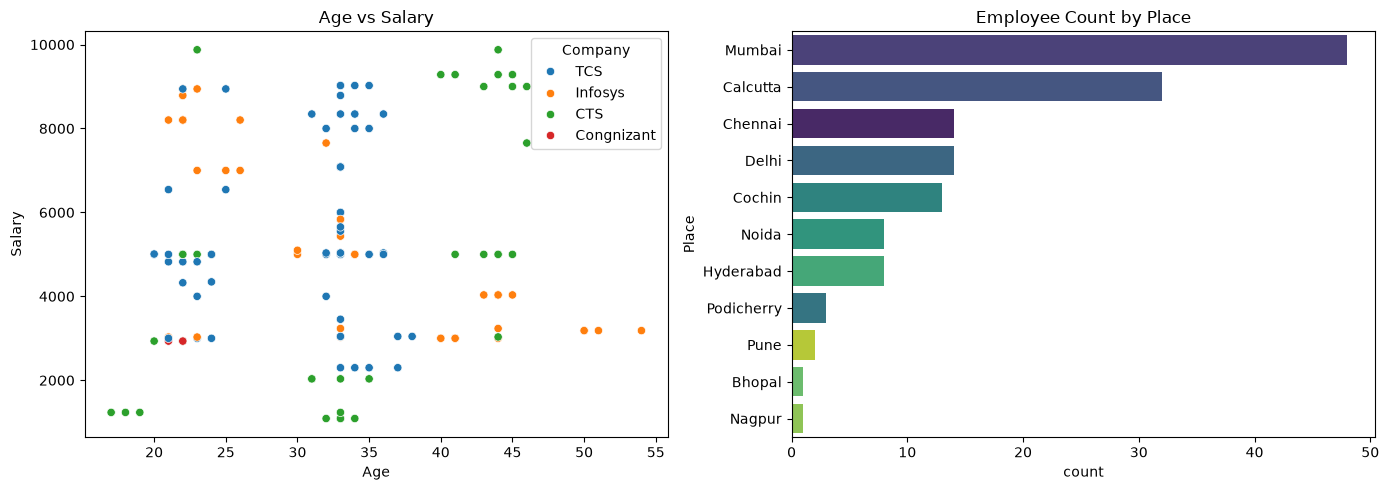

In [26]:
filtered_df = df[(df['Age'] > 40) & (df['Salary'] < 5000)]
print(f"Total employees: {len(filtered_df)}")
display(filtered_df.head())

place_counts = df['Place'].value_counts()
print("\nEmployee count by place:\n", place_counts)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='Age', y='Salary', hue='Company')
plt.title('Age vs Salary')

plt.subplot(1, 2, 2)
sns.countplot(data=df, y='Place', order=place_counts.index, hue='Place' ,palette='viridis',legend=False)
plt.title('Employee Count by Place')

plt.tight_layout()
plt.show()

4-Data Encoding

In [27]:
label_encoder = LabelEncoder()
df['Company_Encoded'] = label_encoder.fit_transform(df['Company'])
df['Country_Encoded'] = label_encoder.fit_transform(df['Country'])

df = pd.get_dummies(df, columns=['Place'], prefix='Place')

df.head()

,Company,Age,Salary,Country,Gender,Company_Encoded,Country_Encoded,Place_Bhopal,Place_Calcutta,Place_Chennai,Place_Cochin,Place_Delhi,Place_Hyderabad,Place_Mumbai,Place_Nagpur,Place_Noida,Place_Podicherry,Place_Pune
0,TCS,20.0,5000.0,India,0,3,0,False,False,True,False,False,False,False,False,False,False,False
1,Infosys,30.0,5000.0,India,0,2,0,False,False,False,False,False,False,True,False,False,False,False
2,TCS,35.0,2300.0,India,0,3,0,False,True,False,False,False,False,False,False,False,False,False
3,Infosys,40.0,3000.0,India,0,2,0,False,False,False,False,True,False,False,False,False,False,False
4,TCS,23.0,4000.0,India,0,3,0,False,False,False,False,False,False,True,False,False,False,False


5-Feature Scaling

In [28]:
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

df[['Age_StandardScaled', 'Salary_StandardScaled']] = std_scaler.fit_transform(df[['Age', 'Salary']])
df[['Age_MinMaxScaled', 'Salary_MinMaxScaled']] = minmax_scaler.fit_transform(df[['Age', 'Salary']])

df[['Age', 'Age_StandardScaled', 'Age_MinMaxScaled', 'Salary', 'Salary_StandardScaled', 'Salary_MinMaxScaled']].head()

,Age,Age_StandardScaled,Age_MinMaxScaled,Salary,Salary_StandardScaled,Salary_MinMaxScaled
0,20.0,-1.484676,0.081081,5000.0,-0.100827,0.445089
1,30.0,-0.267174,0.351351,5000.0,-0.100827,0.445089
2,35.0,0.341577,0.486486,2300.0,-1.243735,0.137817
3,40.0,0.950328,0.621622,3000.0,-0.947426,0.217480
4,23.0,-1.119426,0.162162,4000.0,-0.524127,0.331285
